# The secretome of *Aspergillus oryzae* in the atlas

**Central question.** *The user-supplied secreted-protein list (signal peptide + cell-wall location): where do these
genes sit in the global expression behavior of* A. oryzae*, are they co-expressed with each other, and where are
they in the genome?*

The list is a **biological annotation**, not an expression class: the seven expression classes of `atlas rank genes`
are derived from the atlas' own distributions and are never defined by biology. Here the annotation is *overlaid*
on those classes afterwards ("biology validates, never defines"), and the same set is used as an extra term in the
co-expression enrichment (`atlas coexpr build`).

Each section states a **Question**, runs the **Analysis** (calls into `aoryzae_atlas`), gives the **Answer** (live
numbers from this run) and closes with a **Conclusion**. The notebook can be re-run unchanged whenever the atlas
grows or the list is updated (`atlas geneset import` -> `atlas rank genes` -> `atlas coexpr build`).


## Setup


In [1]:
%matplotlib inline
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from scipy.stats import fisher_exact

from aoryzae_atlas.paths import (
    ANALYSIS_DIR, COEXPRESSION_NEIGHBOURS_FILE, COEXPRESSION_SET_ENRICHMENT_FILE, EXPRESSION_RANK_FILE,
    EXPRESSION_RANK_SUMMARY_FILE, GENE_MASTER_FILE, GENE_SETS_DIR,
)
from aoryzae_atlas.coexpr.network import select_edges
from aoryzae_atlas.genesets.curated import load_gene_sets
from aoryzae_atlas.rank.classes import CLASS_ORDER
from aoryzae_atlas.rank.diagnostics import benjamini_hochberg
from aoryzae_atlas.rank.validation import class_enrichment

warnings.filterwarnings("ignore", category=FutureWarning)
FIG_DIR = ANALYSIS_DIR / "descriptive"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SET_NAME = "secreted"
CLASSES = list(CLASS_ORDER)

CLASS_COLORS = {
    "Constitutive High": "#104281", "Constitutive Core": "#2a78d6", "Constitutive Low": "#86b6ef",
    "Broad Variable": "#4a3aa7", "Context-Specific": "#eda100", "Rare/Silent": "#52514e", "Intermediate": "#a9a79f",
}
SEC_COLOR, REST_COLOR = "#eda100", "#2a78d6"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#c3c2b7", "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
})


def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=160, bbox_inches="tight")


def pct(x, digits=0):
    return f"{100 * x:.{digits}f}%"


def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"


sets = load_gene_sets(GENE_SETS_DIR)
meta, members = sets[SET_NAME]["meta"], set(sets[SET_NAME]["genes"])
resolution = pd.read_csv(GENE_SETS_DIR / f"{SET_NAME}.resolution.tsv", sep="\t", dtype=str, keep_default_na=False)
catalog = pd.read_csv(GENE_MASTER_FILE, sep="\t", dtype={"chromosome": str}, keep_default_na=False).set_index("canonical_gene_id")
catalog["start"], catalog["end"] = pd.to_numeric(catalog["start"]), pd.to_numeric(catalog["end"])
rank = pd.read_parquet(EXPRESSION_RANK_FILE).set_index("gene_id")
rank_scope = json.loads(EXPRESSION_RANK_SUMMARY_FILE.read_text(encoding="utf-8"))
rank["secreted"] = rank.index.isin(members)
rank["description"] = catalog["description"].reindex(rank.index).fillna("")
rank["chromosome"] = catalog["chromosome"].reindex(rank.index)


## 1. What exactly is the set, and how well does it map onto the gene catalog?

**Question.** The list was assembled outside this project (signal peptides from SignalP 6.0, plus the UniProt
"cell wall" annotation). How many of its identifiers resolve to current genes, and which ones need a human decision?

*Decision.* Identifiers are accepted only when they are current canonical ids, retired AO09 ids that FungiDB's
GeneAliases.txt redirects to exactly one current gene, or mappings the user states explicitly. Aliases are listed
as candidates but **never** accepted, because an ambiguous mapping must stay ambiguous.


In [2]:
by_resolution = resolution["resolution"].value_counts()
display(by_resolution.rename("distinct ids").to_frame())
pending = resolution[~resolution["resolution"].isin(["exact", "redirected", "manual"])]
display(pending[["input_id", "resolution", "note"]])
merged = pd.read_csv(GENE_SETS_DIR / f"{SET_NAME}.tsv", sep="\t", dtype=str)
merged = merged[merged["input_ids"].str.contains(";")]
network_genes = None
if COEXPRESSION_NEIGHBOURS_FILE.is_file():
    network_genes = set(pd.read_parquet(COEXPRESSION_NEIGHBOURS_FILE, columns=["gene_id"])["gene_id"])
in_rank = int(rank["secreted"].sum())
display(Markdown(
    f"> **Live scope.** Expression rank: {rank_scope['n_samples']} independent samples, {rank_scope['n_studies']} studies, {len(rank):,} genes "
    f"(generated {rank_scope['generated_at'][:10]}). Gene set `{SET_NAME}` imported {meta['imported_on']}."
))


,distinct ids
resolution,
exact,1191
redirected,41
unresolved,1
alias_candidate,1


,input_id,resolution,note
2,sspB,unresolved,"no match in the gene catalog, redirect map or ..."
1233,AO090011000795-A,alias_candidate,"alias only, NOT accepted; candidates: AO090011..."


> **Live scope.** Expression rank: 343 independent samples, 22 studies, 12,078 genes (generated 2026-10-22). Gene set `secreted` imported 2026-10-26.

In [3]:
display(Markdown(
    f"**Answer.** The list has {meta['n_input_lines']:,} lines, of which {meta['n_duplicate_lines']} duplicate(s), i.e. {meta['n_distinct_tokens']:,} distinct ids. "
    f"{by_resolution.get('exact', 0):,} are current gene ids and {by_resolution.get('redirected', 0)} are retired AO09 ids redirected to a current gene "
    f"({len(merged)} current genes are reached by two retired ids each — loci that were merged between annotation versions). "
    f"The set therefore contains **{meta['n_members']:,} genes**; {in_rank:,} of them are in the expression-rank table"
    + (f" and {len(members & network_genes):,} in the co-expression network (mean TPM >= 1 in the deep biosamples)" if network_genes is not None else "")
    + f". Not in the set: {len(pending)} id(s) — "
    + "; ".join(f"`{r.input_id}` ({r.resolution})" for r in pending.itertuples()) + "."
))


**Answer.** The list has 1,235 lines, of which 1 duplicate(s), i.e. 1,234 distinct ids. 1,191 are current gene ids and 41 are retired AO09 ids redirected to a current gene (9 current genes are reached by two retired ids each — loci that were merged between annotation versions). The set therefore contains **1,223 genes**; 1,222 of them are in the expression-rank table and 888 in the co-expression network (mean TPM >= 1 in the deep biosamples). Not in the set: 2 id(s) — `sspB` (unresolved); `AO090011000795-A` (alias_candidate).

**Conclusion.** The set is almost entirely usable as supplied. The few identifiers left out are left out on purpose
and need the user's decision (a gene symbol that matches nothing in any identifier table, and an alias that points to
a canonical gene whose annotation is *not* the protein the alias names), so they are listed rather than guessed. They
can be added with `atlas geneset import ... --map TOKEN=GENE`. The set records the *union* of the two evidence sources
(SignalP signal peptide, UniProt cell wall); which source supports each gene was not supplied, so the notebook cannot
split the set by evidence.


## 2. A sanity check of the list itself

**Question.** The list comes from predictions (SignalP) and annotation (UniProt), not from this project. Do its members
look secreted in the *independent* GO cellular-component annotation of the reference genome — and do the ids that had to
be redirected from retired AO09 identifiers look as secreted as the ones that matched directly?

*Method.* Each gene of the expression-rank table is put in one category by its GO annotation (FungiDB GAF, propagated
to ancestors when the ontology file is present): **extracellular / cell wall** (extracellular region, cell wall,
fungal-type cell wall), **only nucleus, mitochondrion, cytosol or ribosome**, **annotated otherwise** (membranes, ER,
Golgi, vacuole, unspecific terms — all legitimate places for a protein that enters the secretory pathway), or **no GO
annotation**. GO is itself incomplete and partly inferred, so this is a plausibility check, not a verdict on any gene.


In [4]:
from aoryzae_atlas.paths import FUNGIDB_GO_GAF_FILE, GO_OBO_FILE
from aoryzae_atlas.coexpr.enrichment import load_go_obo, propagate_annotations
from aoryzae_atlas.rank.validation import load_go_annotations

go = load_go_annotations(FUNGIDB_GO_GAF_FILE)
onto = load_go_obo(GO_OBO_FILE) if GO_OBO_FILE.is_file() else None
go_cc = propagate_annotations(go, onto) if onto is not None else go
EXTRACELLULAR = {"GO:0005576", "GO:0005618", "GO:0009277"}
INTRACELLULAR = {"GO:0005634", "GO:0005739", "GO:0005829", "GO:0005840"}
has_ext = set(go_cc.loc[go_cc["go_id"].isin(EXTRACELLULAR), "gene"])
has_int = set(go_cc.loc[go_cc["go_id"].isin(INTRACELLULAR), "gene"])
annotated = set(go["gene"])
CATEGORIES = ["extracellular / cell wall", "only nucleus, mitochondrion, cytosol or ribosome", "annotated otherwise", "no GO annotation"]


def category(gene):
    if gene in has_ext:
        return CATEGORIES[0]
    if gene in has_int:
        return CATEGORIES[1]
    return CATEGORIES[2] if gene in annotated else CATEGORIES[3]


rank["go_category"] = [category(g) for g in rank.index]
accepted = resolution[resolution["resolution"].isin(["exact", "redirected", "manual"])]
res_of_gene = accepted.groupby("canonical_gene_id")["resolution"].agg(lambda x: "redirected" if (x == "redirected").all() else "exact")
rank["id_route"] = rank.index.to_series().map(res_of_gene).fillna("not in set")

counts = pd.crosstab(rank["go_category"], rank["secreted"]).reindex(CATEGORIES).fillna(0).astype(int)
shares = counts / counts.sum()
check = pd.DataFrame({"set members": counts[True], "share of members": shares[True], "other genes": counts[False], "share of other genes": shares[False]})
display(check.round(3))

ext_m, ext_o = int(counts.loc[CATEGORIES[0], True]), int(counts.loc[CATEGORIES[0], False])
or_ext, p_ext = fisher_exact([[ext_m, counts[True].sum() - ext_m], [ext_o, counts[False].sum() - ext_o]])

route = rank[rank["secreted"]].groupby("id_route")["go_category"].value_counts().unstack(fill_value=0).reindex(columns=CATEGORIES, fill_value=0)
route["share extracellular / cell wall"] = route[CATEGORIES[0]] / route.sum(axis=1)
display(route.round(3))
if {"exact", "redirected"} <= set(route.index):
    a, b = route.loc["redirected", CATEGORIES[0]], route.loc["redirected"].iloc[:4].sum() - route.loc["redirected", CATEGORIES[0]]
    c, d = route.loc["exact", CATEGORIES[0]], route.loc["exact"].iloc[:4].sum() - route.loc["exact", CATEGORIES[0]]
    or_route, p_route = fisher_exact([[a, b], [c, d]])
else:
    or_route, p_route = np.nan, np.nan

review = rank[rank["secreted"] & (rank["go_category"] == CATEGORIES[1])].sort_values("median_TPM", ascending=False)
review = review.assign(description=review["description"].str.slice(0, 64))[["id_route", "expression_class", "median_TPM", "description"]]
print(f"Members annotated only to nucleus/mitochondrion/cytosol/ribosome ({len(review)}): worth a second look (SignalP false positive, annotation gap, or an id mismatch)")
print(review.head(15).round(1).to_string())


,set members,share of members,other genes,share of other genes
go_category,,,,
extracellular / cell wall,257,0.210,240,0.022
"only nucleus, mitochondrion, cytosol or ribosome",27,0.022,2648,0.244
annotated otherwise,937,0.767,7962,0.733
no GO annotation,1,0.001,6,0.001


go_category,extracellular / cell wall,"only nucleus, mitochondrion, cytosol or ribosome",annotated otherwise,no GO annotation,share extracellular / cell wall
id_route,,,,,
exact,255,24,910,1,0.214
redirected,2,3,27,0,0.062


Members annotated only to nucleus/mitochondrion/cytosol/ribosome (27): worth a second look (SignalP false positive, annotation gap, or an id mismatch)
                  id_route   expression_class  median_TPM                                                       description
gene_id                                                                                                                    
AO090011000670       exact  Constitutive High       135.5  Ortholog(s) have superoxide dismutase copper chaperone activity,
AO090010000141       exact  Constitutive Core        41.1  Ankyrin repeats (3 copies) | Ankyrin repeat | Ankyrin repeats (m
AO090011000971  redirected  Constitutive Core        33.4  Ortholog(s) have role in thiamine biosynthetic process and cytos
AO090001000768  redirected  Constitutive Core        26.6  Protein similar to polyketide synthases (PKS-like), encoded in a
AO090003000594       exact     Broad Variable        25.1  Ortholog(s) have role in reciprocal meiotic re

In [5]:
n_members = int(counts[True].sum())
n_review = int(counts.loc[CATEGORIES[1], True])
red = route.loc["redirected"] if "redirected" in route.index else None
exa = route.loc["exact"] if "exact" in route.index else None
route_txt = ""
if red is not None and exa is not None:
    route_txt = (f" Among ids that matched directly, {pct(exa['share extracellular / cell wall'])} are extracellular/cell-wall ({int(exa.iloc[:4].sum())} genes); "
                 f"among genes reached through a retired id, {pct(red['share extracellular / cell wall'])} ({int(red.iloc[:4].sum())} genes; Fisher p = {p_route:.2g}).")
display(Markdown(
    f"**Answer.** {pct(shares.loc[CATEGORIES[0], True])} of the {n_members:,} set members carry an extracellular or cell-wall annotation, against "
    f"{pct(shares.loc[CATEGORIES[0], False], 1)} of other genes (odds ratio {or_ext:.1f}, Fisher p = {p_ext:.1g}); {pct(shares.loc[CATEGORIES[1], True])} ({n_review} genes) are annotated only to "
    f"nucleus, mitochondrion, cytosol or ribosome, versus {pct(shares.loc[CATEGORIES[1], False])} of other genes; {pct(shares.loc[CATEGORIES[3], True])} have no GO annotation "
    f"({pct(shares.loc[CATEGORIES[3], False])} of other genes)." + route_txt
))


**Answer.** 21% of the 1,222 set members carry an extracellular or cell-wall annotation, against 2.2% of other genes (odds ratio 11.8, Fisher p = 1e-128); 2% (27 genes) are annotated only to nucleus, mitochondrion, cytosol or ribosome, versus 24% of other genes; 0% have no GO annotation (0% of other genes). Among ids that matched directly, 21% are extracellular/cell-wall (1190 genes); among genes reached through a retired id, 6% (32 genes; Fisher p = 0.045).

In [6]:
red_lower = red is not None and exa is not None and np.isfinite(p_route) and p_route < 0.05 and red["share extracellular / cell wall"] < exa["share extracellular / cell wall"]
display(Markdown(
    f"**Conclusion.** The list is strongly enriched in extracellular / cell-wall annotation (odds ratio {or_ext:.1f}), which supports it as a secretome; it is not "
    f"clean: {n_review} members ({pct(n_review / n_members, 1)}) are annotated only to intracellular compartments, and for most members ({pct(shares.loc[CATEGORIES[2], True])}) "
    "the GO annotation neither confirms nor contradicts secretion (GO location annotation is sparse), so the analyses below describe the list as supplied. "
    + (f"The genes reached through retired AO09 ids look **less** secreted-like than directly matched ones ({pct(red['share extracellular / cell wall'])} of {int(red.iloc[:4].sum())} vs "
       f"{pct(exa['share extracellular / cell wall'])} extracellular/cell-wall; Fisher p = {p_route:.2g}), so those redirects deserve a manual check "
       "(listed in `secreted.resolution.tsv`). " if red_lower else
       "Genes reached through retired AO09 ids look no less secreted-like than directly matched ones (or are too few to tell), so the vetted redirect map is not an obvious source of errors. ")
    + "The table above is a short review list; a SignalP false positive, a gap in GO, or a wrong id mapping can each put a gene there, and only a check of the SignalP/UniProt record settles which."
))


**Conclusion.** The list is strongly enriched in extracellular / cell-wall annotation (odds ratio 11.8), which supports it as a secretome; it is not clean: 27 members (2.2%) are annotated only to intracellular compartments, and for most members (77%) the GO annotation neither confirms nor contradicts secretion (GO location annotation is sparse), so the analyses below describe the list as supplied. The genes reached through retired AO09 ids look **less** secreted-like than directly matched ones (6% of 32 vs 21% extracellular/cell-wall; Fisher p = 0.045), so those redirects deserve a manual check (listed in `secreted.resolution.tsv`). The table above is a short review list; a SignalP false positive, a gap in GO, or a wrong id mapping can each put a gene there, and only a check of the SignalP/UniProt record settles which.

## 3. Where do secreted genes sit among the expression classes?

**Question.** Are secreted genes spread evenly over the seven global expression classes, or concentrated in some?
(Classes come from the atlas' own distributions; the set plays no part in defining them.)


,genes,secreted,share secreted,odds ratio,q (BH)
Constitutive High,1465,41,0.028,0.230,0.000
Constitutive Core,3995,114,0.029,0.185,0.000
Constitutive Low,69,6,0.087,0.845,0.842
Broad Variable,1754,202,0.115,1.187,0.046
Context-Specific,2164,492,0.227,3.702,0.000
Rare/Silent,1031,175,0.170,1.953,0.000
Intermediate,1600,192,0.120,1.251,0.012


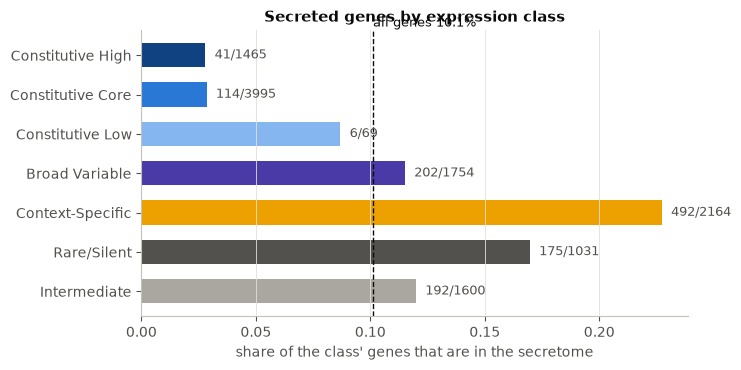

In [7]:
pct_rank = 1 - (rank["global_expression_rank"] - 1) / len(rank)            # 1 = most constitutive
enr = class_enrichment(rank["expression_class"], rank[["secreted"]], pct_rank)
enr = enr.set_index("class").reindex(CLASSES)
counts = pd.crosstab(rank["expression_class"], rank["secreted"]).reindex(CLASSES)
overall = rank["secreted"].mean()
table = pd.DataFrame({
    "genes": counts.sum(axis=1), "secreted": counts[True], "share secreted": counts[True] / counts.sum(axis=1),
    "odds ratio": enr["odds_ratio"], "q (BH)": enr["q_value"],
})
display(table.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(CLASSES))[::-1]
ax.barh(y, table["share secreted"], color=[CLASS_COLORS[c] for c in CLASSES], height=0.62)
ax.axvline(overall, color=INK, lw=1, ls="--")
ax.text(overall, len(CLASSES) - 0.35, f"all genes {pct(overall, 1)}", ha="left", va="bottom", fontsize=9, color=INK)
for yi, (cls, row) in zip(y, table.iterrows()):
    ax.text(row["share secreted"] + 0.004, yi, f"{int(row['secreted'])}/{int(row['genes'])}", va="center", fontsize=9, color=MUTED)
ax.set_yticks(y); ax.set_yticklabels(CLASSES)
ax.set_xlabel("share of the class' genes that are in the secretome"); ax.set_title("Secreted genes by expression class")
ax.grid(axis="y", visible=False)
fig.tight_layout(); save_fig(fig, "secretome_by_class.png"); plt.show()


In [8]:
top = table["odds ratio"].idxmax()
low = table["odds ratio"].idxmin()
sig_up = [c for c in CLASSES if table.loc[c, "odds ratio"] > 1 and table.loc[c, "q (BH)"] < 0.05]
sig_down = [c for c in CLASSES if table.loc[c, "odds ratio"] < 1 and table.loc[c, "q (BH)"] < 0.05]
display(Markdown(
    f"**Answer.** {pct(overall, 1)} of all genes are secreted. The share is highest in **{top}** ({pct(table.loc[top, 'share secreted'], 1)}, odds ratio "
    f"{table.loc[top, 'odds ratio']:.1f}) and lowest in **{low}** ({pct(table.loc[low, 'share secreted'], 1)}, odds ratio {table.loc[low, 'odds ratio']:.2f}). "
    f"Significantly over-represented (BH q < 0.05): {', '.join(sig_up) or 'none'}; under-represented: {', '.join(sig_down) or 'none'}."
))


**Answer.** 10.1% of all genes are secreted. The share is highest in **Context-Specific** (22.7%, odds ratio 3.7) and lowest in **Constitutive Core** (2.9%, odds ratio 0.18). Significantly over-represented (BH q < 0.05): Broad Variable, Context-Specific, Rare/Silent, Intermediate; under-represented: Constitutive High, Constitutive Core.

In [9]:
strong_up = [c for c in CLASSES if table.loc[c, "odds ratio"] >= 1.5 and table.loc[c, "q (BH)"] < 0.05]
weak_up = [c for c in CLASSES if 1 < table.loc[c, "odds ratio"] < 1.5 and table.loc[c, "q (BH)"] < 0.05]
strong_down = [c for c in CLASSES if table.loc[c, "odds ratio"] <= 1 / 1.5 and table.loc[c, "q (BH)"] < 0.05]
fmt = lambda cs: ", ".join(f"{c} (odds ratio {table.loc[c, 'odds ratio']:.2f})" for c in cs) or "no class"
display(Markdown(
    "**Conclusion.** Secreted proteins are not a random draw from the expression classes. Strongly over-represented: "
    f"{fmt(strong_up)}; only slightly over-represented: {fmt(weak_up)}; strongly under-represented: {fmt(strong_down)}. The secretome is therefore concentrated among genes that are "
    "lowly, rarely or conditionally detected and depleted among the constitutive classes — consistent with the expectation that secreted hydrolases and cell-wall "
    "proteins are induced by carbon source, growth phase or morphology rather than expressed everywhere (an expectation, not something this table proves). "
    "The classes are relative to this atlas and the atlas is dominated by a few strains and studies, so the claim is about *this collection of transcriptomes*, not a universal property."
))


**Conclusion.** Secreted proteins are not a random draw from the expression classes. Strongly over-represented: Context-Specific (odds ratio 3.70), Rare/Silent (odds ratio 1.95); only slightly over-represented: Broad Variable (odds ratio 1.19), Intermediate (odds ratio 1.25); strongly under-represented: Constitutive High (odds ratio 0.23), Constitutive Core (odds ratio 0.18). The secretome is therefore concentrated among genes that are lowly, rarely or conditionally detected and depleted among the constitutive classes — consistent with the expectation that secreted hydrolases and cell-wall proteins are induced by carbon source, growth phase or morphology rather than expressed everywhere (an expectation, not something this table proves). The classes are relative to this atlas and the atlas is dominated by a few strains and studies, so the claim is about *this collection of transcriptomes*, not a universal property.

## 4. Level, stability and specificity

**Question.** The classes compress three separate axes. Looking at the continuous scores, how do secreted genes
differ from the rest in expression level, stability and specificity (Tau)?


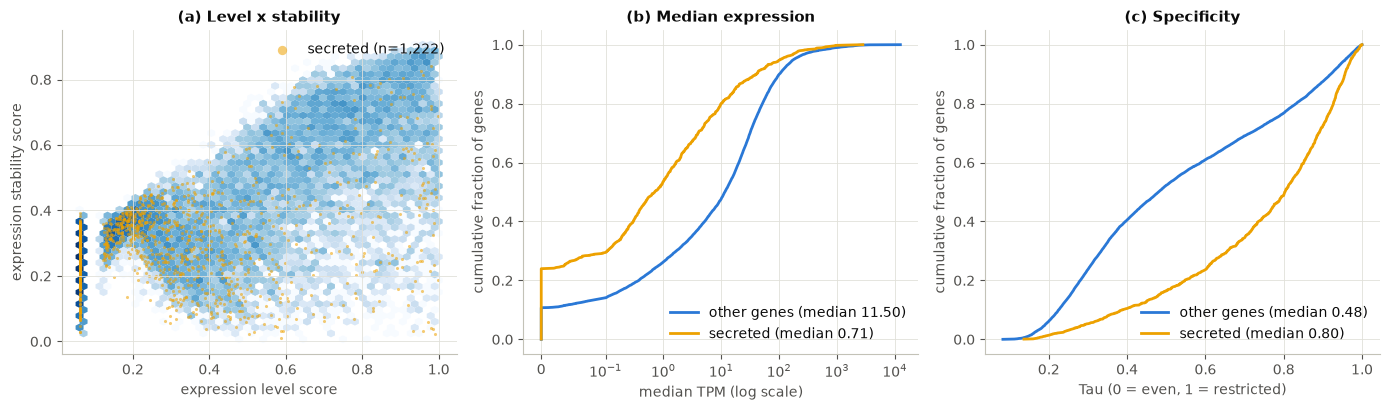

,median_TPM,expression_level_score,expression_stability_score,expression_specificity_score,Tau,prevalence_TPM_1
secreted,,,,,,
other genes,11.495,0.532,0.397,0.462,0.480,0.983
secreted,0.710,0.267,0.305,0.763,0.803,0.414


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
rest = rank[~rank["secreted"]]
sec = rank[rank["secreted"]]
hb = axes[0].hexbin(rest["expression_level_score"], rest["expression_stability_score"], gridsize=45, cmap="Blues", mincnt=1, bins="log", linewidths=0)
axes[0].scatter(sec["expression_level_score"], sec["expression_stability_score"], s=5, color=SEC_COLOR, alpha=0.55, linewidths=0, label=f"secreted (n={len(sec):,})")
axes[0].set_xlabel("expression level score"); axes[0].set_ylabel("expression stability score")
axes[0].set_title("(a) Level x stability"); axes[0].legend(frameon=False, loc="upper right", markerscale=3)
for ax, col, label, title in (
    (axes[1], "median_TPM", "median TPM (log scale)", "(b) Median expression"),
    (axes[2], "Tau", "Tau (0 = even, 1 = restricted)", "(c) Specificity"),
):
    for data, color, name in ((rest, REST_COLOR, "other genes"), (sec, SEC_COLOR, "secreted")):
        vals = np.sort(data[col].dropna().to_numpy())
        ax.plot(vals, np.arange(1, len(vals) + 1) / len(vals), color=color, lw=2, label=f"{name} (median {np.median(vals):.2f})")
    if col == "median_TPM":
        ax.set_xscale("symlog", linthresh=0.1)
    ax.set_xlabel(label); ax.set_ylabel("cumulative fraction of genes"); ax.set_title(title); ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); save_fig(fig, "secretome_scores.png"); plt.show()

summary = rank.groupby("secreted")[["median_TPM", "expression_level_score", "expression_stability_score", "expression_specificity_score", "Tau", "prevalence_TPM_1"]].median()
summary.index = summary.index.map({False: "other genes", True: "secreted"})
display(summary.round(3))


In [11]:
s_, o_ = summary.loc["secreted"], summary.loc["other genes"]
ks_stat = lambda col: float(np.max(np.abs(
    np.searchsorted(np.sort(sec[col].dropna()), np.sort(rank[col].dropna()), side="right") / sec[col].notna().sum()
    - np.searchsorted(np.sort(rest[col].dropna()), np.sort(rank[col].dropna()), side="right") / rest[col].notna().sum())))
display(Markdown(
    f"**Answer.** Median TPM is {s_['median_TPM']:.2f} for secreted genes versus {o_['median_TPM']:.2f} for the others; the median level score is "
    f"{s_['expression_level_score']:.2f} versus {o_['expression_level_score']:.2f}, the stability score {s_['expression_stability_score']:.2f} versus "
    f"{o_['expression_stability_score']:.2f}, and Tau {s_['Tau']:.2f} versus {o_['Tau']:.2f}. The largest gap between the two distributions "
    f"(Kolmogorov-Smirnov distance) is {ks_stat('median_TPM'):.2f} for median TPM and {ks_stat('Tau'):.2f} for Tau."
))


**Answer.** Median TPM is 0.71 for secreted genes versus 11.50 for the others; the median level score is 0.27 versus 0.53, the stability score 0.31 versus 0.40, and Tau 0.80 versus 0.48. The largest gap between the two distributions (Kolmogorov-Smirnov distance) is 0.33 for median TPM and 0.37 for Tau.

**Conclusion.** The typical secreted gene is expressed at a lower median level, in fewer samples and in a more
restricted way than the typical gene — but the distributions overlap and a minority of secreted genes are among the
most highly and most evenly expressed genes of the atlas (Section 5 lists them with their annotation). So "secreted" is not a synonym
for "condition-specific": it is better read as an enrichment of conditional expression inside a set that also holds
abundant, constitutively expressed proteins (Section 5 lists them with their annotation).


## 5. Which secreted genes are the most expressed, and which the most specific?

**Question.** Which individual secreted genes stand out — as the most abundant and most evenly expressed, and as the
most restricted to a few samples (candidates for condition-dependent secretion)?


In [12]:
def show(df, n=12):
    out = df.head(n)[["expression_class", "median_TPM", "Tau", "prevalence_TPM_1", "description"]].copy()
    out["description"] = out["description"].str.slice(0, 70)
    return out.round(3)


print("Most expressed secreted genes (median TPM over independent samples)")
print(show(sec.sort_values("median_TPM", ascending=False)).to_string())
print()
print("Most specific secreted genes (rank_most_specific; ties broken by peak TPM)")
print(show(sec.sort_values("rank_most_specific")).to_string())
print()
print("Secreted genes with the highest global (constitutive) rank")
print(show(sec.sort_values("global_expression_rank")).to_string())


Most expressed secreted genes (median TPM over independent samples)
                 expression_class  median_TPM    Tau  prevalence_TPM_1                                                             description
gene_id                                                                                                                                       
AO090005000583     Broad Variable    2801.919  0.259             0.991  Ortholog of A. nidulans FGSC A4 : AN1549, A. fumigatus Af293 : Afu8g05
AO090103000056  Constitutive High    2082.369  0.137             1.000  Ortholog of A. nidulans FGSC A4 : AN3310, AN1449, AN7654, A. fumigatus
AO090020000517     Broad Variable    1289.773  0.179             1.000                     Ortholog(s) have serine-type endopeptidase activity
AO090023000944     Broad Variable     938.552  0.375             0.936                                                           Alpha-amylase
AO090023000918  Constitutive High     921.627  0.220             1.000  Or

In [13]:
top_expr = sec.sort_values("median_TPM", ascending=False).head(12)
n_amyl = int(sec["description"].str.contains("amylase|glucoamylase|glucan", case=False).sum())
display(Markdown(
    f"**Answer.** Among the {len(sec):,} secreted genes in the rank table, {int((sec['median_TPM'] >= 100).sum())} have a median TPM of at least 100 and "
    f"{int((sec['median_TPM'] >= 10).sum())} at least 10, while {int((sec['median_TPM'] < 1).sum())} ({pct((sec['median_TPM'] < 1).mean())}) are below 1 TPM in the median sample. "
    f"The 12 most expressed belong to the classes: {', '.join(f'{k} ({v})' for k, v in top_expr['expression_class'].value_counts().items())}. "
    f"{int((sec['expression_class'] == 'Constitutive High').sum())} secreted genes are Constitutive High and {int((sec['expression_class'] == 'Context-Specific').sum())} are Context-Specific."
))


**Answer.** Among the 1,222 secreted genes in the rank table, 65 have a median TPM of at least 100 and 245 at least 10, while 655 (54%) are below 1 TPM in the median sample. The 12 most expressed belong to the classes: Broad Variable (7), Constitutive High (5). 41 secreted genes are Constitutive High and 492 are Context-Specific.

In [14]:
spec12 = sec.sort_values("rank_most_specific").head(12)
n_det = (spec12["prevalence_TPM_1"] * rank_scope["n_samples"]).round()
display(Markdown(
    "**Conclusion.** The top of the tables above is the practical shortlist: the first table for abundant secreted proteins the atlas sees in most samples, "
    "the second for secreted proteins seen in very few of them. Read the second one with care: the 12 most specific genes reach 1 TPM in a median of "
    f"{int(np.median(n_det))} of {rank_scope['n_samples']} samples, so they are better described as *rarely detected* than as a reproducible condition-specific program; "
    "which condition drives them has to be read from the sample annotations, not from the class. Product descriptions are those of the reference annotation "
    "and many are generic ('Ortholog(s) have ...')."
))


**Conclusion.** The top of the tables above is the practical shortlist: the first table for abundant secreted proteins the atlas sees in most samples, the second for secreted proteins seen in very few of them. Read the second one with care: the 12 most specific genes reach 1 TPM in a median of 1 of 343 samples, so they are better described as *rarely detected* than as a reproducible condition-specific program; which condition drives them has to be read from the sample annotations, not from the class. Product descriptions are those of the reference annotation and many are generic ('Ortholog(s) have ...').

## 6. Is the pattern a study or strain artefact?

**Question.** The atlas is structured by strain and study. Do secreted genes carry the study/strain-dominance and
borderline-class flags more often than other genes — i.e. is their apparent condition-specificity partly an artefact of
which studies happen to be in the atlas?


In [15]:
flag_names = ["possible_study_effect", "possible_strain_effect", "borderline_class", "low_sample_support"]
flags = pd.DataFrame({f: rank["quality_flags"].fillna("").str.contains(f) for f in flag_names})
rows = []
for f in flag_names:
    a, b = int((flags[f] & rank["secreted"]).sum()), int((flags[f] & ~rank["secreted"]).sum())
    c, d = int((~flags[f] & rank["secreted"]).sum()), int((~flags[f] & ~rank["secreted"]).sum())
    odds, p = fisher_exact([[a, b], [c, d]])
    rows.append({"flag": f, "share of secreted": a / (a + c), "share of other genes": b / (b + d), "odds ratio": odds, "p": p})
flag_table = pd.DataFrame(rows).set_index("flag")
flag_table["q (BH)"] = benjamini_hochberg(flag_table["p"].to_numpy())
display(flag_table.round(4))

within = []
for cls in CLASSES:
    d = rank[rank["expression_class"] == cls]
    within.append({"class": cls, "secreted": int(d["secreted"].sum()),
                   "study-effect flag, secreted": flags.loc[d.index[d["secreted"]], "possible_study_effect"].mean() if d["secreted"].any() else np.nan,
                   "study-effect flag, other": flags.loc[d.index[~d["secreted"]], "possible_study_effect"].mean()})
display(pd.DataFrame(within).set_index("class").round(3))


,share of secreted,share of other genes,odds ratio,p,q (BH)
flag,,,,,
possible_study_effect,0.0245,0.0368,0.6596,0.0275,0.0516
possible_strain_effect,0.0033,0.0061,0.5369,0.3171,0.3171
borderline_class,0.0483,0.0636,0.7474,0.0387,0.0516
low_sample_support,0.0033,0.0005,7.1271,0.0087,0.0346


,secreted,"study-effect flag, secreted","study-effect flag, other"
class,,,
Constitutive High,41,0.073,0.086
Constitutive Core,114,0.009,0.032
Constitutive Low,6,0.000,0.000
Broad Variable,202,0.054,0.051
Context-Specific,492,0.016,0.025
Rare/Silent,175,0.023,0.012
Intermediate,192,0.016,0.014


In [16]:
worse = flag_table[(flag_table["odds ratio"] > 1) & (flag_table["q (BH)"] < 0.05)].index.tolist()
better = flag_table[(flag_table["odds ratio"] < 1) & (flag_table["q (BH)"] < 0.05)].index.tolist()
display(Markdown(
    "**Answer.** " + "; ".join(f"{f}: {pct(r['share of secreted'], 1)} of secreted vs {pct(r['share of other genes'], 1)} of other genes (odds ratio {r['odds ratio']:.2f})" for f, r in flag_table.iterrows())
    + f". Flags significantly more common among secreted genes (BH q < 0.05): {', '.join(worse) or 'none'}; significantly less common: {', '.join(better) or 'none'}."
))


**Answer.** possible_study_effect: 2.5% of secreted vs 3.7% of other genes (odds ratio 0.66); possible_strain_effect: 0.3% of secreted vs 0.6% of other genes (odds ratio 0.54); borderline_class: 4.8% of secreted vs 6.4% of other genes (odds ratio 0.75); low_sample_support: 0.3% of secreted vs 0.0% of other genes (odds ratio 7.13). Flags significantly more common among secreted genes (BH q < 0.05): low_sample_support; significantly less common: none.

In [17]:
more = flag_table[(flag_table["odds ratio"] > 1) & (flag_table["q (BH)"] < 0.05)]
n_low = int((flags["low_sample_support"] & rank["secreted"]).sum())
within_tab = pd.DataFrame(within).set_index("class")
within_tab = within_tab[within_tab["secreted"] >= 10]
higher = within_tab.index[within_tab["study-effect flag, secreted"] > within_tab["study-effect flag, other"] + 0.005].tolist()
display(Markdown(
    "**Conclusion.** The flags are descriptive checks, never exclusions. Secreted genes are "
    + ("**not** flagged for study or strain dominance more often than other genes" if not any(f in more.index for f in ("possible_study_effect", "possible_strain_effect"))
       else "flagged for study or strain dominance **more** often than other genes")
    + f" (odds ratios {flag_table.loc['possible_study_effect', 'odds ratio']:.2f} and {flag_table.loc['possible_strain_effect', 'odds ratio']:.2f}). Holding the class fixed (second table), "
    f"the study-effect flag is no more common among secreted genes in {len(within_tab) - len(higher)} of the {len(within_tab)} classes with at least 10 secreted genes"
    + (f" (higher in {', '.join(higher)})" if higher else "") + ", so the class-level pattern of Section 3 does not look like the product of one study or strain. "
    + (f"The one flag that is more common among secreted genes is low_sample_support, which concerns only {n_low} genes. " if "low_sample_support" in more.index else "")
    + "The classes are re-derived on every `atlas refresh`, so this check should be repeated as studies are added."
))


**Conclusion.** The flags are descriptive checks, never exclusions. Secreted genes are **not** flagged for study or strain dominance more often than other genes (odds ratios 0.66 and 0.54). Holding the class fixed (second table), the study-effect flag is no more common among secreted genes in 5 of the 6 classes with at least 10 secreted genes (higher in Rare/Silent), so the class-level pattern of Section 3 does not look like the product of one study or strain. The one flag that is more common among secreted genes is low_sample_support, which concerns only 4 genes. The classes are re-derived on every `atlas refresh`, so this check should be repeated as studies are added.

## 7. Where are secreted genes in the genome?

**Question.** Are secreted genes spread evenly over the chromosomes, and do they sit next to each other along a
chromosome more often than chance (clusters such as tandem hydrolase families)?


,genes,secreted,share,odds ratio,q (BH)
chromosome,,,,,
Chr8_A_oryzae_RIB40,1091,146,0.1338,1.4231,0.0040
Chr5_A_oryzae_RIB40,1485,176,0.1185,1.2272,0.0766
Chr7_A_oryzae_RIB40,906,104,0.1148,1.1662,0.3379
Chr6_A_oryzae_RIB40,1319,139,0.1054,1.0524,0.8919
Chr4_A_oryzae_RIB40,1528,156,0.1021,1.0116,1.0000
Chr3_A_oryzae_RIB40,1654,147,0.0889,0.8483,0.1898
Chr2_A_oryzae_RIB40,2019,177,0.0877,0.8289,0.0867
Chr1_A_oryzae_RIB40,2048,177,0.0864,0.8134,0.0766
contig_11.1_A_oryzae_RIB40,6,0,0.0000,0.0000,1.0000


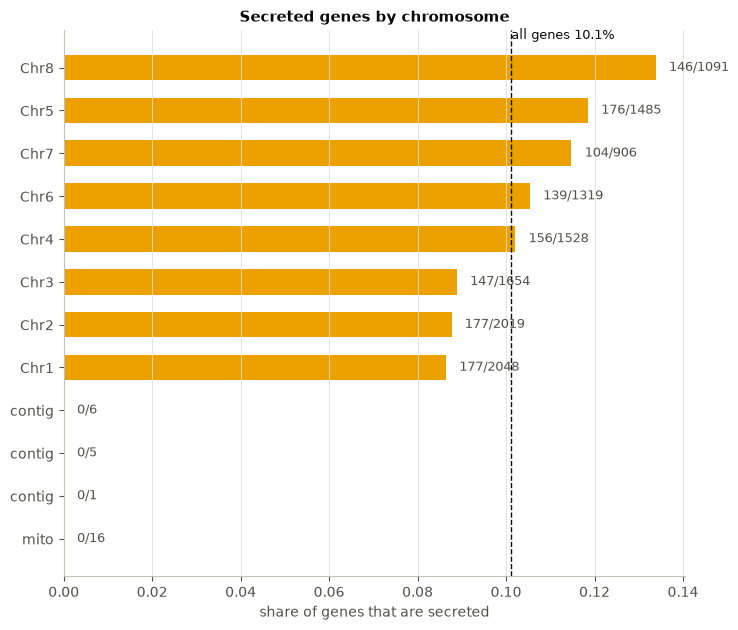

In [18]:
genome = catalog.loc[catalog.index.isin(rank.index), ["chromosome", "start", "end"]].copy()
genome["secreted"] = genome.index.isin(members)
genome = genome.sort_values(["chromosome", "start"])
chrom = genome.groupby("chromosome").agg(genes=("secreted", "size"), secreted=("secreted", "sum"))
chrom["share"] = chrom["secreted"] / chrom["genes"]
all_share = genome["secreted"].mean()
pvals, odds = [], []
for ch, row in chrom.iterrows():
    o, p = fisher_exact([[row["secreted"], genome["secreted"].sum() - row["secreted"]], [row["genes"] - row["secreted"], (~genome["secreted"]).sum() - (row["genes"] - row["secreted"])]])
    odds.append(o); pvals.append(p)
chrom["odds ratio"], chrom["q (BH)"] = odds, benjamini_hochberg(np.array(pvals))
chrom = chrom.sort_values("share", ascending=False)
display(chrom.round(4))

# adjacency: consecutive genes (same chromosome) that are both secreted, versus label shuffles of the ordered gene list
ordered = genome["secreted"].to_numpy()
same_chr = (genome["chromosome"].to_numpy()[1:] == genome["chromosome"].to_numpy()[:-1])
observed_pairs = int((ordered[1:] & ordered[:-1] & same_chr).sum())
rng = np.random.default_rng(0)
null_pairs = np.array([int((p[1:] & p[:-1] & same_chr).sum()) for p in (rng.permutation(ordered) for _ in range(2000))])
p_adj = (1 + int((null_pairs >= observed_pairs).sum())) / (1 + len(null_pairs))

fig, ax = plt.subplots(figsize=(7.5, 0.4 * len(chrom) + 1.6))
ax.barh(range(len(chrom))[::-1], chrom["share"], color=SEC_COLOR, height=0.6)
ax.axvline(all_share, color=INK, lw=1, ls="--"); ax.text(all_share, len(chrom) - 0.4, f"all genes {pct(all_share, 1)}", fontsize=9, va="bottom")
ax.set_yticks(range(len(chrom))[::-1]); ax.set_yticklabels([c.split("_")[0] for c in chrom.index])
for yi, (ch, row) in zip(range(len(chrom))[::-1], chrom.iterrows()):
    ax.text(row["share"] + 0.003, yi, f"{int(row['secreted'])}/{int(row['genes'])}", va="center", fontsize=9, color=MUTED)
ax.set_xlabel("share of genes that are secreted"); ax.set_title("Secreted genes by chromosome"); ax.grid(axis="y", visible=False)
fig.tight_layout(); save_fig(fig, "secretome_by_chromosome.png"); plt.show()


In [19]:
sig_chr = chrom[chrom["q (BH)"] < 0.05]
display(Markdown(
    f"**Answer.** Share of secreted genes per chromosome ranges from {pct(chrom['share'].min(), 1)} to {pct(chrom['share'].max(), 1)} (all genes: {pct(all_share, 1)}); "
    f"{len(sig_chr)} of {len(chrom)} chromosomes differ significantly from the genome-wide share (BH q < 0.05): "
    + (", ".join(f"{c.split('_')[0]} ({pct(r['share'], 1)}, odds ratio {r['odds ratio']:.2f})" for c, r in sig_chr.iterrows()) or "none") + ". "
    f"Consecutive genes that are both secreted: {observed_pairs} observed versus {null_pairs.mean():.0f} expected under shuffled labels "
    f"({observed_pairs / max(null_pairs.mean(), 1e-9):.1f}x, permutation p {fmt_p(p_adj)})."
))


**Answer.** Share of secreted genes per chromosome ranges from 0.0% to 13.4% (all genes: 10.1%); 1 of 12 chromosomes differ significantly from the genome-wide share (BH q < 0.05): Chr8 (13.4%, odds ratio 1.42). Consecutive genes that are both secreted: 244 observed versus 123 expected under shuffled labels (2.0x, permutation p < 0.001).

In [20]:
display(Markdown(
    f"**Conclusion.** The secretome is spread over the chromosomes almost evenly ({len(sig_chr)} of {len(chrom)} sequences differ significantly"
    + (f", {', '.join(c.split('_')[0] for c in sig_chr.index)} being richer" if len(sig_chr) else "")
    + f"); the small contigs and the mitochondrial sequence hold too few genes to say anything. What stands out is local: consecutive secreted genes are "
    f"{observed_pairs / max(null_pairs.mean(), 1e-9):.1f}x more frequent than under shuffled labels (permutation p {fmt_p(p_adj)}), "
    + ("which indicates clusters of secreted genes (for instance tandem duplications or co-regulated families) that deserve a locus-level look. " if p_adj < 0.05 and observed_pairs > null_pairs.mean() else "which gives no sign of clustering. ")
    + "The permutation keeps the gene order and shuffles only the labels, so it tests clustering, not chromosome-level richness."
))


**Conclusion.** The secretome is spread over the chromosomes almost evenly (1 of 12 sequences differ significantly, Chr8 being richer); the small contigs and the mitochondrial sequence hold too few genes to say anything. What stands out is local: consecutive secreted genes are 2.0x more frequent than under shuffled labels (permutation p < 0.001), which indicates clusters of secreted genes (for instance tandem duplications or co-regulated families) that deserve a locus-level look. The permutation keeps the gene order and shuffles only the labels, so it tests clustering, not chromosome-level richness.

## 8. Are secreted genes co-expressed with each other?

**Question.** Using the co-expression network (`atlas coexpr build`), do a secreted gene's best neighbours tend to be
secreted too — beyond the base rate of secreted genes in the network — and are there network modules made mostly of
secreted genes?


In [21]:
if not COEXPRESSION_NEIGHBOURS_FILE.is_file():
    display(Markdown("**Not available.** Run `atlas coexpr build` first."))
    coexpr_ok = False
else:
    coexpr_ok = True
    nb_all = pd.read_parquet(COEXPRESSION_NEIGHBOURS_FILE)
    modes = list(dict.fromkeys(nb_all["mode"]))
    net = {m: set(nb_all.loc[nb_all["mode"] == m, "gene_id"]) for m in modes}
    rows = []
    for m in modes:
        d = nb_all[nb_all["mode"] == m]
        base = len(members & net[m]) / len(net[m])
        d = d.assign(src_sec=d["gene_id"].isin(members), nb_sec=d["neighbour_id"].isin(members))
        for lo, hi in ((1, 5), (6, 10), (11, 25), (26, int(d["rank"].max()))):
            sub = d[(d["rank"] >= lo) & (d["rank"] <= hi)]
            rows.append({
                "mode": m, "neighbour ranks": f"{lo}-{hi}", "base rate": base,
                "secreted genes: share of neighbours secreted": sub.loc[sub["src_sec"], "nb_sec"].mean(),
                "other genes: share of neighbours secreted": sub.loc[~sub["src_sec"], "nb_sec"].mean(),
            })
    nb_table = pd.DataFrame(rows)
    display(nb_table.round(3))


,mode,neighbour ranks,base rate,secreted genes: share of neighbours secreted,other genes: share of neighbours secreted
0,all_samples,1-5,0.088,0.191,0.060
1,all_samples,6-10,0.088,0.169,0.064
2,all_samples,11-25,0.088,0.162,0.064
3,all_samples,26-50,0.088,0.149,0.064
4,within_study,1-5,0.088,0.189,0.053
5,within_study,6-10,0.088,0.153,0.052
6,within_study,11-25,0.088,0.137,0.051
7,within_study,26-50,0.088,0.120,0.051


In [22]:
if coexpr_ok:
    set_enr = pd.read_parquet(COEXPRESSION_SET_ENRICHMENT_FILE) if COEXPRESSION_SET_ENRICHMENT_FILE.is_file() else pd.DataFrame()
    lines = []
    for m in modes:
        t = nb_table[(nb_table["mode"] == m) & (nb_table["neighbour ranks"].str.startswith("1-"))].iloc[0]
        lines.append(f"`{m}`: {pct(t['secreted genes: share of neighbours secreted'], 0)} of the top-5 neighbours of a secreted gene are secreted versus "
                     f"{pct(t['other genes: share of neighbours secreted'], 0)} for other genes (base rate in the network {pct(t['base rate'], 0)})")
    enr_txt = ""
    if len(set_enr):
        parts = []
        for m in modes:
            e = set_enr[(set_enr["mode"] == m) & (set_enr["term"] == f"SET:{SET_NAME}")]
            genes_m = net[m]
            sec_in = members & genes_m
            parts.append(f"`{m}`: {pct(e['gene_id'].isin(sec_in).sum() / len(sec_in))} of secreted genes have a neighbourhood enriched in the secretome (q <= 0.05) versus "
                         f"{pct(e['gene_id'].isin(genes_m - sec_in).sum() / len(genes_m - sec_in))} of other genes")
        enr_txt = " Neighbourhood enrichment in the set: " + "; ".join(parts) + "."
    display(Markdown("**Answer.** " + "; ".join(lines) + "." + enr_txt))


**Answer.** `all_samples`: 19% of the top-5 neighbours of a secreted gene are secreted versus 6% for other genes (base rate in the network 9%); `within_study`: 19% of the top-5 neighbours of a secreted gene are secreted versus 5% for other genes (base rate in the network 9%). Neighbourhood enrichment in the set: `all_samples`: 41% of secreted genes have a neighbourhood enriched in the secretome (q <= 0.05) versus 10% of other genes; `within_study`: 33% of secreted genes have a neighbourhood enriched in the secretome (q <= 0.05) versus 6% of other genes.

In [23]:
if coexpr_ok:
    MR_CUT, SUPPORT_MIN = 2, 0.2
    for m in modes:
        edges = select_edges(nb_all[nb_all["mode"] == m], MR_CUT, SUPPORT_MIN if m == "all_samples" else None)
        genes_m = pd.Index(sorted(net[m]))
        pos = {g: i for i, g in enumerate(genes_m)}
        adj = sparse.coo_matrix((np.ones(len(edges)), (edges["a"].map(pos), edges["b"].map(pos))), shape=(len(genes_m),) * 2).tocsr()
        _, labels = connected_components(((adj + adj.T) > 0), directed=False)
        comp = pd.DataFrame({"gene": genes_m, "component": labels, "secreted": genes_m.isin(members)})
        agg = comp.groupby("component").agg(genes=("gene", "size"), secreted=("secreted", "sum"))
        agg["share secreted"] = agg["secreted"] / agg["genes"]
        mods = agg[(agg["genes"] >= 5) & (agg["share secreted"] >= 0.5)].sort_values(["secreted", "share secreted"], ascending=False)
        mods["e.g."] = [
            "; ".join(rank["description"].reindex(comp.loc[(comp["component"] == c) & comp["secreted"], "gene"].head(2)).fillna("").str.slice(0, 38))
            for c in mods.index
        ]
        print(f"=== {m}: modules (mutual rank <= {MR_CUT}) of >= 5 genes with >= 50% secreted genes: {len(mods)} of {int((agg['genes'] >= 5).sum())} modules of >= 5 genes ===")
        print(mods.head(10).round(2).to_string())
        globals()[f"modules_{m}"] = mods
        globals()[f"n_modules_{m}"] = int((agg["genes"] >= 5).sum())


=== all_samples: modules (mutual rank <= 2) of >= 5 genes with >= 50% secreted genes: 5 of 257 modules of >= 5 genes ===
           genes  secreted  share secreted                                                                            e.g.
component                                                                                                                 
1641           7         5            0.71  Ortholog(s) have carbohydrate binding ; Has domain(s) with predicted catalytic
2315           5         4            0.80  Ortholog of Aspergillus flavus NRRL 33; Ortholog of A. nidulans FGSC A4 : AN92
1381           7         4            0.57              Putative cell wall protein; Has domain(s) with predicted triglycer
2674           5         3            0.60  Ortholog of A. oryzae RIB40 : AO090020; Fungal hydrophobin | domain-containing
47             6         3            0.50  Ortholog of Aspergillus flavus NRRL 33; Ortholog of Aspergillus flavus NRRL 33


=== within_study: modules (mutual rank <= 2) of >= 5 genes with >= 50% secreted genes: 5 of 261 modules of >= 5 genes ===
           genes  secreted  share secreted                                                                            e.g.
component                                                                                                                 
1548           9         7            0.78  Ortholog of Aspergillus flavus NRRL 33; Ortholog of A. oryzae RIB40 : AO090020
970            7         4            0.57  Ortholog(s) have carbohydrate binding ; Ortholog of A. nidulans FGSC A4 : AN29
3319           5         3            0.60             Ortholog of A. fumigatus Af293 : Afu7g; protein of unknown function
150            6         3            0.50  Ortholog of Aspergillus flavus NRRL 33; Ortholog(s) have extracellular region 
1439           6         3            0.50                            Alpha-amylase involved in starch hydro; Glucoamylase


In [24]:
if coexpr_ok:
    txt = "; ".join(f"`{m}`: {len(globals()[f'modules_{m}'])} modules" + (f" (largest: {int(globals()[f'modules_{m}']['secreted'].iloc[0])} secreted genes of {int(globals()[f'modules_{m}']['genes'].iloc[0])})" if len(globals()[f'modules_{m}']) else "") for m in modes)
    display(Markdown(f"**Answer (modules).** Network modules of at least 5 genes made of at least half secreted genes, at mutual rank <= {MR_CUT}: {txt}."))


**Answer (modules).** Network modules of at least 5 genes made of at least half secreted genes, at mutual rank <= 2: `all_samples`: 5 modules (largest: 5 secreted genes of 7); `within_study`: 5 modules (largest: 7 secreted genes of 9).

In [25]:
if coexpr_ok:
    ratios = {m: nb_table[(nb_table["mode"] == m) & nb_table["neighbour ranks"].str.startswith("1-")].iloc[0] for m in modes}
    display(Markdown(
        "**Conclusion.** Secreted genes do co-vary with each other: "
        + "; ".join(f"in `{m}` their best neighbours are secreted {r['secreted genes: share of neighbours secreted'] / r['other genes: share of neighbours secreted']:.1f}x more often than those of other genes "
                    f"and {r['secreted genes: share of neighbours secreted'] / r['base rate']:.1f}x the base rate" for m, r in ratios.items())
        + ", and the tendency decays with neighbour rank. But it is a tendency, not a single secretome module: only "
        + "; ".join(f"{len(globals()[f'modules_{m}'])} of {globals()[f'n_modules_{m}']} modules of >= 5 genes in `{m}`" for m in modes)
        + " are made mostly of secreted genes at this strict cut: secreted genes do not form a module of their own, the modules they appear in also contain "
        "non-secreted genes. These are statistical relationships in this atlas, not regulatory interactions, and connected components at a strict mutual rank are the coarsest possible module definition."
    ))


**Conclusion.** Secreted genes do co-vary with each other: in `all_samples` their best neighbours are secreted 3.2x more often than those of other genes and 2.2x the base rate; in `within_study` their best neighbours are secreted 3.5x more often than those of other genes and 2.1x the base rate, and the tendency decays with neighbour rank. But it is a tendency, not a single secretome module: only 5 of 257 modules of >= 5 genes in `all_samples`; 5 of 261 modules of >= 5 genes in `within_study` are made mostly of secreted genes at this strict cut: secreted genes do not form a module of their own, the modules they appear in also contain non-secreted genes. These are statistical relationships in this atlas, not regulatory interactions, and connected components at a strict mutual rank are the coarsest possible module definition.

## 9. Consistency and limitations

**Question.** Does what this notebook used match what is stored on disk, and what can the secreted set not tell us?


In [26]:
stored = pd.read_csv(GENE_SETS_DIR / f"{SET_NAME}.tsv", sep="\t", dtype=str)
accepted = resolution[resolution["resolution"].isin(["exact", "redirected", "manual"])]
assert set(stored["canonical_gene_id"]) == set(accepted["canonical_gene_id"]) == members
assert len(members) == meta["n_members"]
assert members <= set(catalog.index), "every member must be a current canonical gene"
display(Markdown(
    f"**Consistency check passed.** The stored set has {len(members):,} genes, equal to the accepted rows of the resolution table and to the metadata, "
    f"and every member is a current canonical gene id; {int(rank['secreted'].sum()):,} are present in the expression-rank table."
))


**Consistency check passed.** The stored set has 1,223 genes, equal to the accepted rows of the resolution table and to the metadata, and every member is a current canonical gene id; 1,222 are present in the expression-rank table.

**Limitations.**

- **Union of evidence.** The set merges SignalP 6.0 signal-peptide predictions with the UniProt "cell wall" annotation;
  per-gene evidence was not supplied, so the set cannot be split into "predicted secreted", "cell wall" and "both".
  Proteins secreted without a classical signal peptide, and GPI-anchored proteins not annotated as cell wall, are not
  captured unless they carry one of the two labels.
- **Predictions are predictions.** A signal peptide marks entry to the secretory pathway; the final location (cell
  wall, medium, membrane, vacuole) is a separate question.
- **Two identifiers need a decision** (Section 1), a few members look intracellular (Section 2), and 41 ids were retired by the current annotation and redirected
  by FungiDB's alias table — vetted, one-to-one, but worth a glance in `secreted.resolution.tsv`.
- **Expression classes are relative to this atlas** and are re-derived at every refresh; the atlas is structured by
  strain and study (Section 6), so class-level statements describe this collection of transcriptomes.
- **Co-expression links are statistical**, built on biosamples with enough depth (Section 8 inherits the network's
  parameters); a gene absent from the network (mean TPM < 1) cannot be assessed there.
